<a href="https://colab.research.google.com/github/shambhavijatti/Artificial_Intelligence_Lab_B_28/blob/master/ML_Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler

print("LIBRARIES IMPORTED SUCCESSFULLY!")

LIBRARIES IMPORTED SUCCESSFULLY!


In [ ]:
# Load dataset

df = pd.read_csv("Students Performance Dataset.csv")

print("DATASET LOADEED SUCCESSFULLY!")
print("SHAPE OF DATASET:", df.shape)

DATASET LOADEED SUCCESSFULLY!
SHAPE OF DATASET: (5000, 23)


In [ ]:
# Create a copy of the original dataset

df_original = df.copy()

print("ORIGINAL DATASET BACKUP CREATED.")

ORIGINAL DATASET BACKUP CREATED.


In [ ]:
# Display first 5 rows

df.head()

,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Projects_Score,Total_Score,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night
0,S1000,Omar,Williams,student0@university.com,Female,22,Mathematics,97.36,40.61,59.61,...,62.84,59.8865,F,10.3,Yes,No,Master's,Medium,1,5.9
1,S1001,Maria,Brown,student1@university.com,Male,18,Business,97.71,57.27,74.00,...,98.23,81.9170,B,27.1,No,No,High School,Low,4,4.3
2,S1002,Ahmed,Jones,student2@university.com,Male,24,Engineering,99.52,41.84,63.85,...,91.22,67.7170,D,12.4,Yes,No,High School,Low,9,6.1
3,S1003,Omar,Williams,student3@university.com,Female,24,Engineering,90.38,45.65,44.44,...,55.48,51.6535,F,25.5,No,Yes,High School,Low,8,4.9
4,S1004,John,Smith,student4@university.com,Female,23,CS,59.41,53.13,61.77,...,87.43,71.4030,C,13.3,Yes,No,Master's,Medium,6,4.5


In [ ]:
# Display last 5 rows

df.tail()

,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Projects_Score,Total_Score,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night
4995,S5995,Ahmed,Jones,student4995@university.com,Male,19,CS,96.09,45.86,45.63,...,51.66,53.5470,F,7.8,No,No,Master's,Medium,10,4.5
4996,S5996,Emma,Brown,student4996@university.com,Male,19,Mathematics,96.30,78.67,47.42,...,52.33,59.0240,F,24.2,No,Yes,NaN,Medium,4,7.2
4997,S5997,John,Brown,student4997@university.com,Female,24,CS,89.94,50.84,65.83,...,97.89,74.7560,C,7.6,No,Yes,NaN,High,5,6.6
4998,S5998,Sara,Davis,student4998@university.com,Male,23,Engineering,99.09,55.44,57.45,...,84.74,68.6585,D,14.5,Yes,No,PhD,Medium,10,5.9
4999,S5999,Maria,Brown,student4999@university.com,Female,21,Mathematics,90.33,93.29,88.42,...,66.23,78.7485,C,29.9,Yes,Yes,PhD,High,2,5.3


In [ ]:
# Check dataset dimensions

print("NUMBER OF ROWS:", df.shape[0])
print("NUMBER OF COLUMNS:", df.shape[1])

NUMBER OF ROWS: 5000
NUMBER OF COLUMNS: 23


In [ ]:
# Display column names

print("COLUMNS IN THE DATASET:\n")

for i, column in enumerate(df.columns, 1):
    print(i, ".", column)

COLUMNS IN THE DATASET:

1 . Student_ID
2 . First_Name
3 . Last_Name
4 . Email
5 . Gender
6 . Age
7 . Department
8 . Attendance (%)
9 . Midterm_Score
10 . Final_Score
11 . Assignments_Avg
12 . Quizzes_Avg
13 . Participation_Score
14 . Projects_Score
15 . Total_Score
16 . Grade
17 . Study_Hours_per_Week
18 . Extracurricular_Activities
19 . Internet_Access_at_Home
20 . Parent_Education_Level
21 . Family_Income_Level
22 . Stress_Level (1-10)
23 . Sleep_Hours_per_Night


In [ ]:
# Check data types

print(df.dtypes)

Student_ID                     object
First_Name                     object
Last_Name                      object
Email                          object
Gender                         object
Age                             int64
Department                     object
Attendance (%)                float64
Midterm_Score                 float64
Final_Score                   float64
Assignments_Avg               float64
Quizzes_Avg                   float64
Participation_Score           float64
Projects_Score                float64
Total_Score                   float64
Grade                          object
Study_Hours_per_Week          float64
Extracurricular_Activities     object
Internet_Access_at_Home        object
Parent_Education_Level         object
Family_Income_Level            object
Stress_Level (1-10)             int64
Sleep_Hours_per_Night         float64
dtype: object


In [ ]:
# Detailed information about dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  5000 non-null   object 
 1   First_Name                  5000 non-null   object 
 2   Last_Name                   5000 non-null   object 
 3   Email                       5000 non-null   object 
 4   Gender                      5000 non-null   object 
 5   Age                         5000 non-null   int64  
 6   Department                  5000 non-null   object 
 7   Attendance (%)              5000 non-null   float64
 8   Midterm_Score               5000 non-null   float64
 9   Final_Score                 5000 non-null   float64
 10  Assignments_Avg             5000 non-null   float64
 11  Quizzes_Avg                 5000 non-null   float64
 12  Participation_Score         5000 non-null   float64
 13  Projects_Score              5000 

In [ ]:
#Missing Values

missing_values = df.isnull().sum()

print("MISSING VALUES:")
print(missing_values)

MISSING VALUES:
Student_ID                       0
First_Name                       0
Last_Name                        0
Email                            0
Gender                           0
Age                              0
Department                       0
Attendance (%)                   0
Midterm_Score                    0
Final_Score                      0
Assignments_Avg                  0
Quizzes_Avg                      0
Participation_Score              0
Projects_Score                   0
Total_Score                      0
Grade                            0
Study_Hours_per_Week             0
Extracurricular_Activities       0
Internet_Access_at_Home          0
Parent_Education_Level        1025
Family_Income_Level              0
Stress_Level (1-10)              0
Sleep_Hours_per_Night            0
dtype: int64


In [ ]:
# 4. Check Missing Values

print("\n========== MISSING VALUES ==========")

missing_values = df.isnull().sum()

print(missing_values)

print("\nCOLUMNS CONTAINING MISSING VALUES:")
print(missing_values[missing_values > 0])



========== MISSING VALUES ==========
Student_ID                       0
First_Name                       0
Last_Name                        0
Email                            0
Gender                           0
Age                              0
Department                       0
Attendance (%)                   0
Midterm_Score                    0
Final_Score                      0
Assignments_Avg                  0
Quizzes_Avg                      0
Participation_Score              0
Projects_Score                   0
Total_Score                      0
Grade                            0
Study_Hours_per_Week             0
Extracurricular_Activities       0
Internet_Access_at_Home          0
Parent_Education_Level        1025
Family_Income_Level              0
Stress_Level (1-10)              0
Sleep_Hours_per_Night            0
dtype: int64

COLUMNS CONTAINING MISSING VALUES:
Parent_Education_Level    1025
dtype: int64


In [ ]:
# 5. Check Duplicate Records

print("\n========== DUPLICATE RECORDS ==========")

duplicate_count = df.duplicated().sum()

print("NUMBER OF DUPLICATE RECORDS:", duplicate_count)

# Remove duplicates if any exist
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)


========== DUPLICATE RECORDS ==========
NUMBER OF DUPLICATE RECORDS: 0
Dataset shape after removing duplicates: (5000, 23)


In [ ]:
# 7. Select Academic Features

academic_features = [
    'Attendance (%)',
    'Midterm_Score',
    'Assignments_Avg',
    'Quizzes_Avg',
    'Participation_Score',
    'Projects_Score',
    'Study_Hours_per_Week'
]

print("\n========== SELECTED FEATURES ==========")
print(academic_features)


========== SELECTED FEATURES ==========
['Attendance (%)', 'Midterm_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Study_Hours_per_Week']


In [ ]:
# 8. Check Statistical Summary

print("\n========== STATISTICAL SUMMARY ==========")
display(df[academic_features].describe())


========== STATISTICAL SUMMARY ==========


,Attendance (%),Midterm_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Study_Hours_per_Week
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000
mean,75.356076,70.701924,74.956320,74.836214,49.963720,74.78305,17.521140
std,14.392716,17.436325,14.404287,14.423848,28.989785,14.54243,7.193035
min,50.010000,40.000000,50.000000,50.000000,0.000000,50.00000,5.000000
25%,62.945000,55.707500,62.340000,62.357500,25.075000,61.97000,11.500000
50%,75.670000,70.860000,75.090000,74.905000,49.600000,74.54000,17.400000
75%,87.862500,85.760000,87.352500,87.292500,75.500000,87.63000,23.700000
max,100.000000,99.990000,99.990000,99.990000,100.000000,100.00000,30.000000


In [ ]:
# 9. Detect Outliers Using IQR

print("\n========== OUTLIER DETECTION ==========")

Q1 = df[academic_features].quantile(0.25)
Q3 = df[academic_features].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (
    (df[academic_features] < lower_bound) |
    (df[academic_features] > upper_bound)
)

print("Potential outliers in each feature:")
print(outliers.sum())


========== OUTLIER DETECTION ==========
Potential outliers in each feature:
Attendance (%)          0
Midterm_Score           0
Assignments_Avg         0
Quizzes_Avg             0
Participation_Score     0
Projects_Score          0
Study_Hours_per_Week    0
dtype: int64


In [ ]:
# 10. Create Academic Risk Target

print("\n========== CREATING ACADEMIC RISK TARGET ==========")

# First check available grades
print("Grade distribution:")
print(df['Grade'].value_counts())


# D and F = At Risk
# A, B and C = Not At Risk

df['Academic_Risk'] = df['Grade'].apply(
    lambda x: 'At Risk' if x in ['D', 'F'] else 'Not At Risk'
)

print("\nAcademic Risk distribution:")
print(df['Academic_Risk'].value_counts())



========== CREATING ACADEMIC RISK TARGET ==========
Grade distribution:
Grade
C    2307
D    1760
B     638
F     279
A      16
Name: count, dtype: int64

Academic Risk distribution:
Academic_Risk
Not At Risk    2961
At Risk        2039
Name: count, dtype: int64


In [ ]:
# 11. Label Encoding of Target

print("\n========== LABEL ENCODING ==========")

df['Academic_Risk_Num'] = df['Academic_Risk'].map({
    'Not At Risk': 0,
    'At Risk': 1
})

print(df[['Grade', 'Academic_Risk', 'Academic_Risk_Num']].head(10))


========== LABEL ENCODING ==========
  Grade Academic_Risk  Academic_Risk_Num
0     F       At Risk                  1
1     B   Not At Risk                  0
2     D       At Risk                  1
3     F       At Risk                  1
4     C   Not At Risk                  0
5     D       At Risk                  1
6     B   Not At Risk                  0
7     C   Not At Risk                  0
8     D       At Risk                  1
9     B   Not At Risk                  0


In [ ]:
# 12. Create Input X and Target y

print("\n========== INPUT AND TARGET ==========")

X = df[academic_features]

y = df['Academic_Risk_Num']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget:")
print("0 = Not At Risk")
print("1 = At Risk")


========== INPUT AND TARGET ==========
Input features shape: (5000, 7)
Target shape: (5000,)

Input features:
['Attendance (%)', 'Midterm_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Study_Hours_per_Week']

Target:
0 = Not At Risk
1 = At Risk


In [ ]:
# 13. Check Class Imbalance

print("\n========== CLASS DISTRIBUTION ==========")

class_counts = y.value_counts()

print(class_counts)

print("\nClass percentages:")
print((y.value_counts(normalize=True) * 100).round(2))



========== CLASS DISTRIBUTION ==========
Academic_Risk_Num
0    2961
1    2039
Name: count, dtype: int64

Class percentages:
Academic_Risk_Num
0    59.22
1    40.78
Name: proportion, dtype: float64


In [ ]:
# 14. Train-Test Split

print("\n========== TRAIN-TEST SPLIT ==========")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())



========== TRAIN-TEST SPLIT ==========
Training data shape: (4000, 7)
Testing data shape: (1000, 7)

Training target distribution:
Academic_Risk_Num
0    2369
1    1631
Name: count, dtype: int64

Testing target distribution:
Academic_Risk_Num
0    592
1    408
Name: count, dtype: int64


In [ ]:
# 15. Feature Standardization

print("\n========== FEATURE STANDARDIZATION ==========")

scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaler to test data
X_test_scaled = scaler.transform(X_test)

print("Standardization completed successfully!")

print("\nScaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)


========== FEATURE STANDARDIZATION ==========
Standardization completed successfully!

Scaled training data shape: (4000, 7)
Scaled testing data shape: (1000, 7)


In [ ]:
# 16. Final Preprocessing Summary

print("\n================================================")
print("       PHASE 4 PREPROCESSING COMPLETED")
print("================================================")

print("Original dataset shape:", (5000, 23))
print("Final input features:", len(academic_features))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nSelected Features:")
for feature in academic_features:
    print("-", feature)

print("\nTarget:")
print("- 0 = Not At Risk")
print("- 1 = At Risk")

print("\nPreprocessing techniques performed:")
print("1. Missing value checking")
print("2. Duplicate record checking")
print("3. Data type checking")
print("4. Outlier detection using IQR")
print("5. Feature selection")
print("6. Label encoding of target")
print("7. Class imbalance checking")
print("8. Train-test splitting")
print("9. Feature standardization")

print("\nPhase 4 completed successfully!")


       PHASE 4 PREPROCESSING COMPLETED
Original dataset shape: (5000, 23)
Final input features: 7
Training records: 4000
Testing records: 1000

Selected Features:
- Attendance (%)
- Midterm_Score
- Assignments_Avg
- Quizzes_Avg
- Participation_Score
- Projects_Score
- Study_Hours_per_Week

Target:
- 0 = Not At Risk
- 1 = At Risk

Preprocessing techniques performed:
1. Missing value checking
2. Duplicate record checking
3. Data type checking
4. Outlier detection using IQR
5. Feature selection
6. Label encoding of target
7. Class imbalance checking
8. Train-test splitting
9. Feature standardization

Phase 4 completed successfully!


EXPLAINABLE ML FOR STUDENT ACADEMIC RISK PREDICTION



PHASE 5: EXPLORATORY DATA ANALYSIS

Dataset Shape:
(5000, 25)

First 5 Records:


,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night,Academic_Risk,Academic_Risk_Num
0,S1000,Omar,Williams,student0@university.com,Female,22,Mathematics,97.36,40.61,59.61,...,F,10.3,Yes,No,Master's,Medium,1,5.9,At Risk,1
1,S1001,Maria,Brown,student1@university.com,Male,18,Business,97.71,57.27,74.00,...,B,27.1,No,No,High School,Low,4,4.3,Not At Risk,0
2,S1002,Ahmed,Jones,student2@university.com,Male,24,Engineering,99.52,41.84,63.85,...,D,12.4,Yes,No,High School,Low,9,6.1,At Risk,1
3,S1003,Omar,Williams,student3@university.com,Female,24,Engineering,90.38,45.65,44.44,...,F,25.5,No,Yes,High School,Low,8,4.9,At Risk,1
4,S1004,John,Smith,student4@university.com,Female,23,CS,59.41,53.13,61.77,...,C,13.3,Yes,No,Master's,Medium,6,4.5,Not At Risk,0



Statistical Summary:


,Attendance (%),Midterm_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Study_Hours_per_Week
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000
mean,75.356076,70.701924,74.956320,74.836214,49.963720,74.78305,17.521140
std,14.392716,17.436325,14.404287,14.423848,28.989785,14.54243,7.193035
min,50.010000,40.000000,50.000000,50.000000,0.000000,50.00000,5.000000
25%,62.945000,55.707500,62.340000,62.357500,25.075000,61.97000,11.500000
50%,75.670000,70.860000,75.090000,74.905000,49.600000,74.54000,17.400000
75%,87.862500,85.760000,87.352500,87.292500,75.500000,87.63000,23.700000
max,100.000000,99.990000,99.990000,99.990000,100.000000,100.00000,30.000000


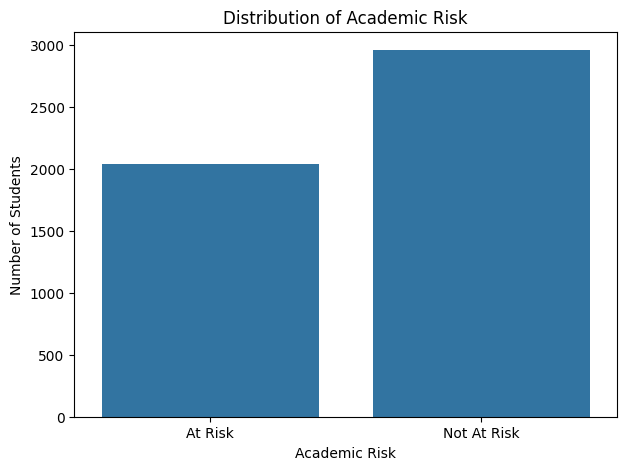

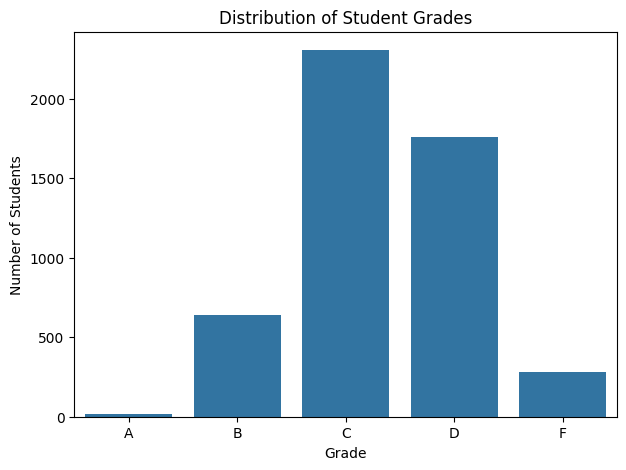

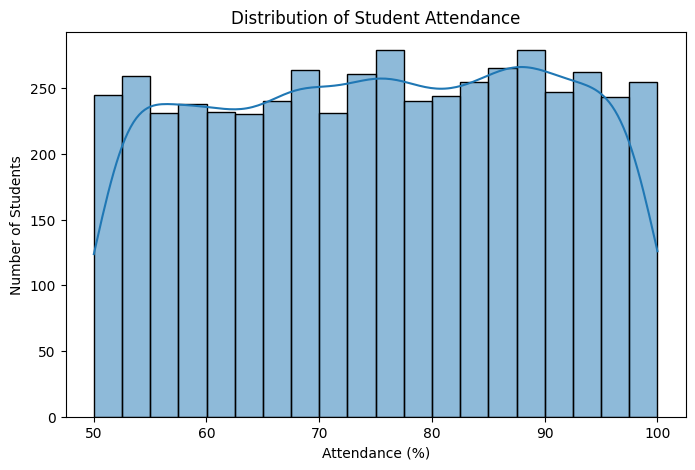

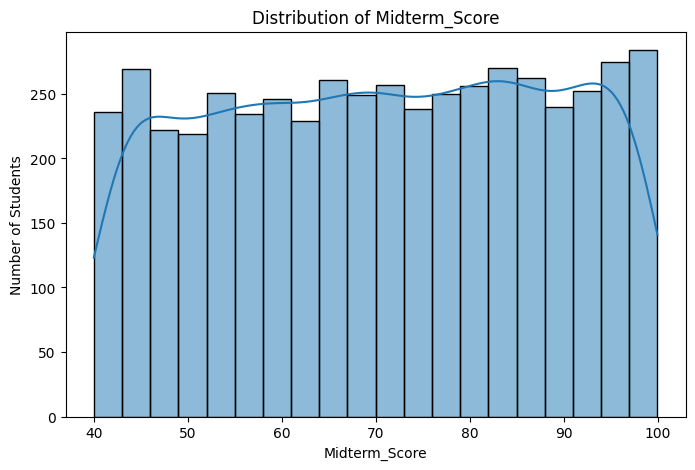

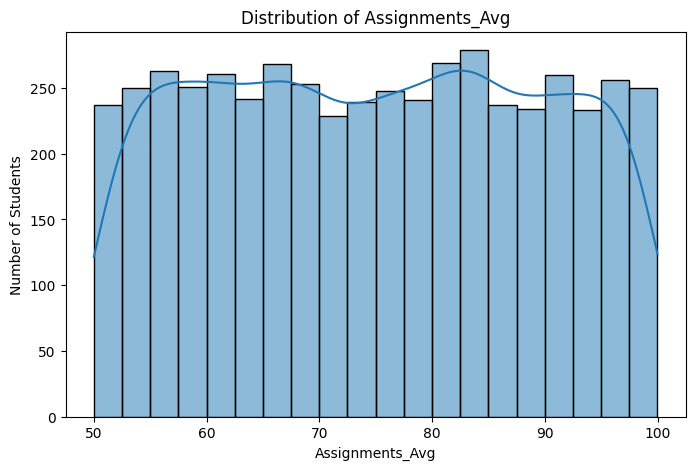

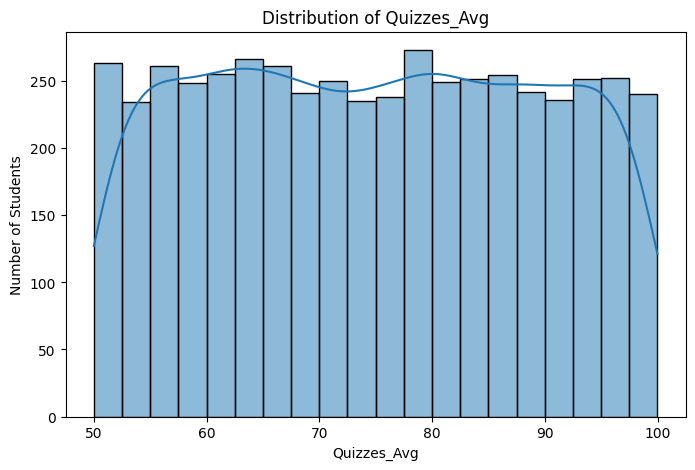

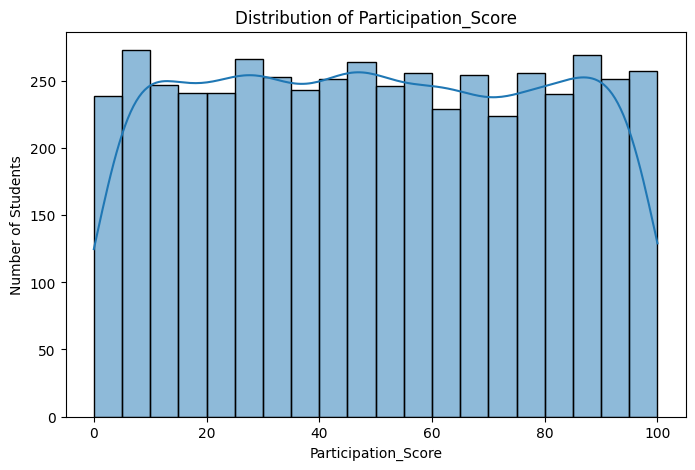

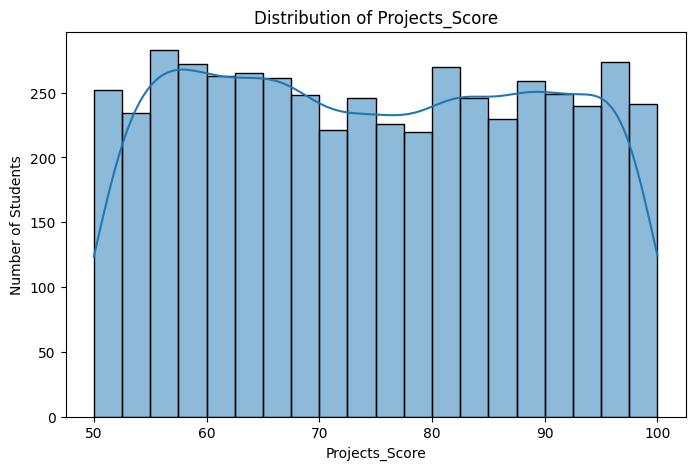

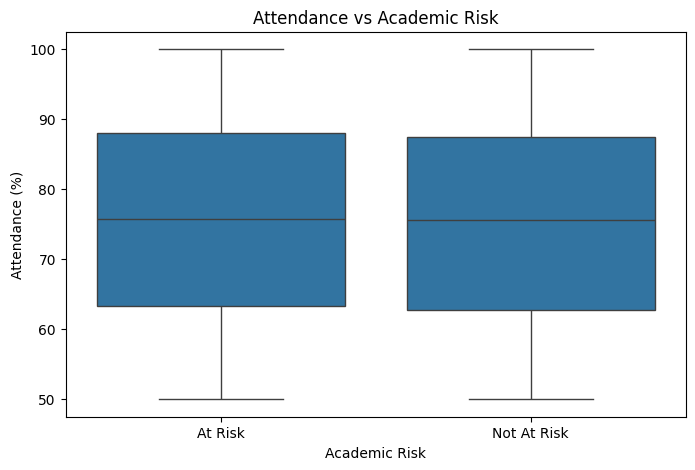

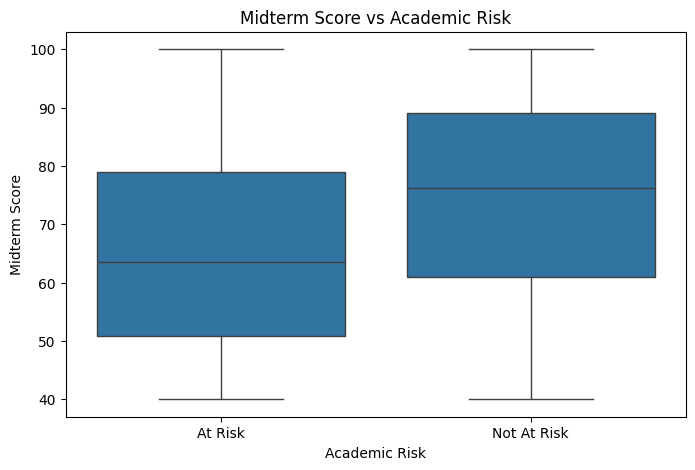

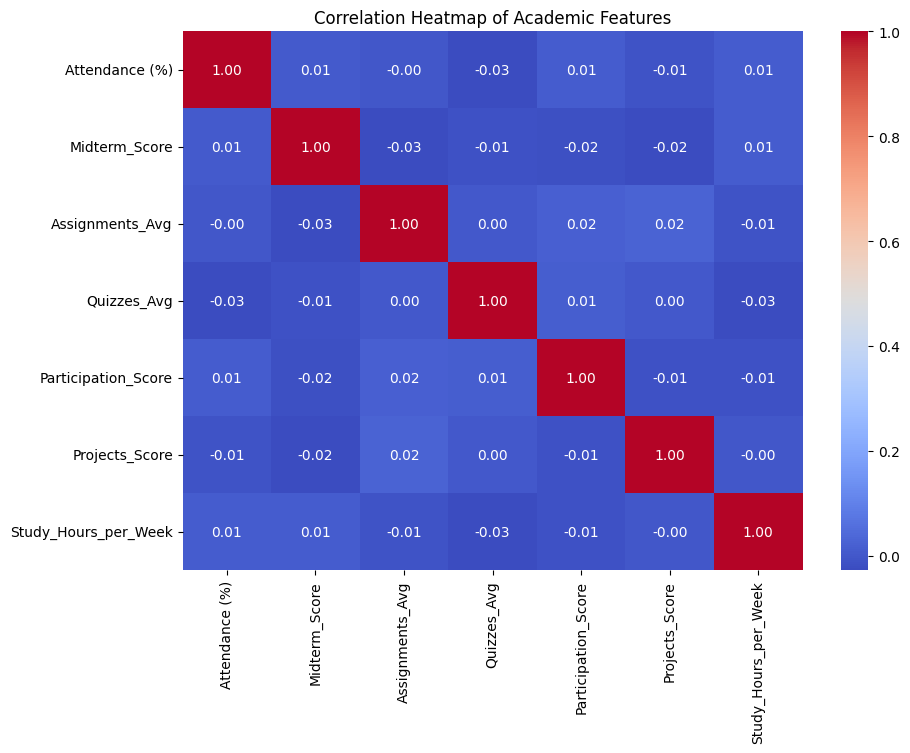




PHASE 6: FEATURE ENGINEERING

Final Features Used by the ML Models:
1. Attendance (%)
2. Midterm_Score
3. Assignments_Avg
4. Quizzes_Avg
5. Participation_Score
6. Projects_Score
7. Study_Hours_per_Week

Target:
0 = Not At Risk
1 = At Risk

Missing Values in Selected Features:
Attendance (%)          0
Midterm_Score           0
Assignments_Avg         0
Quizzes_Avg             0
Participation_Score     0
Projects_Score          0
Study_Hours_per_Week    0
dtype: int64



PHASE 7: TRAINING AND TEST DATA

Training records: 4000
Testing records: 1000

Training class distribution:
Academic_Risk_Num
0    2369
1    1631
Name: count, dtype: int64

Testing class distribution:
Academic_Risk_Num
0    592
1    408
Name: count, dtype: int64



PHASE 8: MACHINE LEARNING MODEL DEVELOPMENT

Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!



PHASE 9:

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8000,0.7311,0.8064,0.7669,0.8876
1,Decision Tree,0.7500,0.6508,0.8358,0.7318,0.8307
2,Random Forest,0.7990,0.7358,0.7917,0.7627,0.8767





PHASE 10: BEST MODEL SELECTION

Best Model:
Logistic Regression

The best model was selected based on the highest F1 Score.



PHASE 11: DETAILED BEST MODEL EVALUATION

Classification Report:
              precision    recall  f1-score   support

 Not At Risk       0.86      0.80      0.82       592
     At Risk       0.73      0.81      0.77       408

    accuracy                           0.80      1000
   macro avg       0.79      0.80      0.80      1000
weighted avg       0.81      0.80      0.80      1000



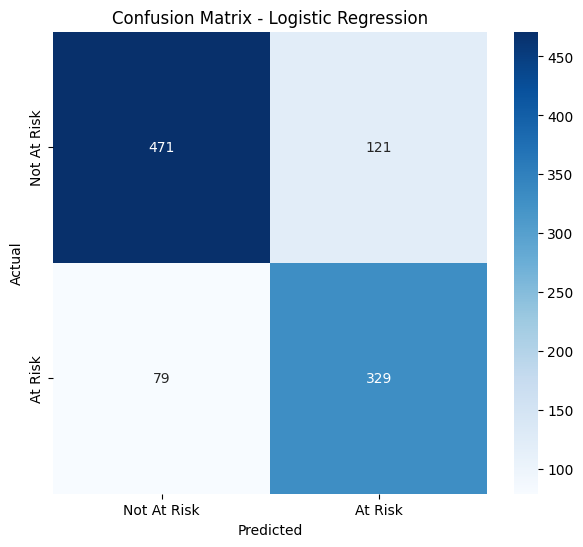

<Figure size 800x600 with 0 Axes>

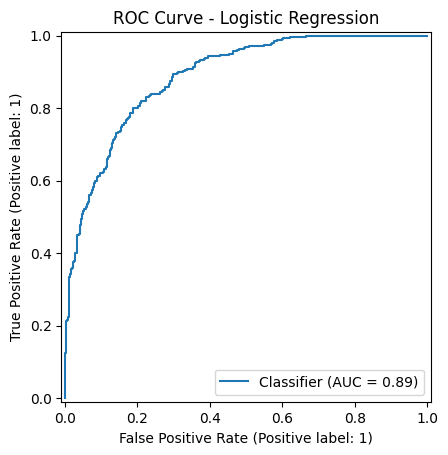




PHASE 12: CROSS-VALIDATION

Logistic Regression
F1 Scores: [0.7725 0.7575 0.7483 0.7494 0.7569]
Mean F1 Score: 0.7569

Decision Tree
F1 Scores: [0.7204 0.7172 0.6887 0.7003 0.7352]
Mean F1 Score: 0.7124

Random Forest
F1 Scores: [0.768  0.7485 0.7331 0.743  0.7429]
Mean F1 Score: 0.7471



PHASE 13: FEATURE IMPORTANCE

Feature Importance:


,Feature,Importance
5,Projects_Score,1.618463
1,Midterm_Score,0.981673
2,Assignments_Avg,0.920539
4,Participation_Score,0.564881
3,Quizzes_Avg,0.563781
6,Study_Hours_per_Week,0.048461
0,Attendance (%),0.025245


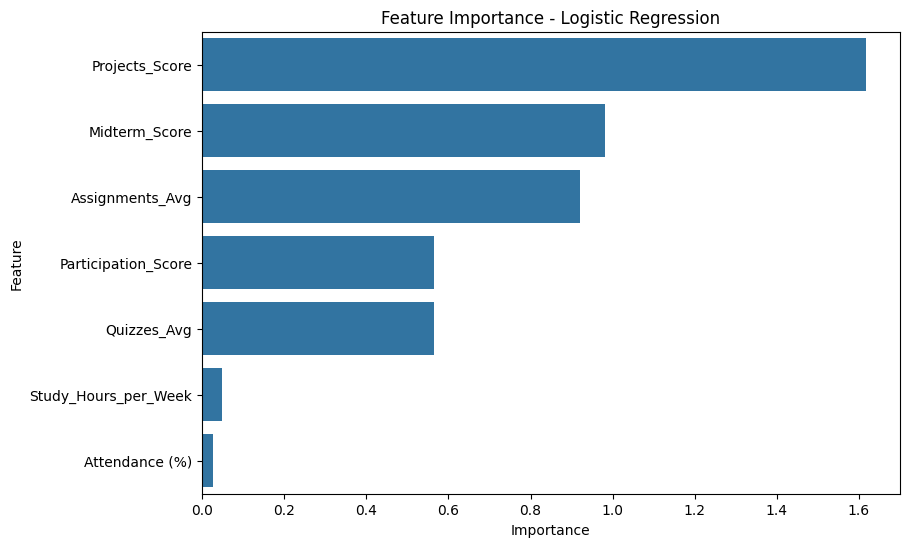




PHASE 14: EXPLAINABLE AI USING SHAP



Generating SHAP explanations...

SHAP Summary Plot:


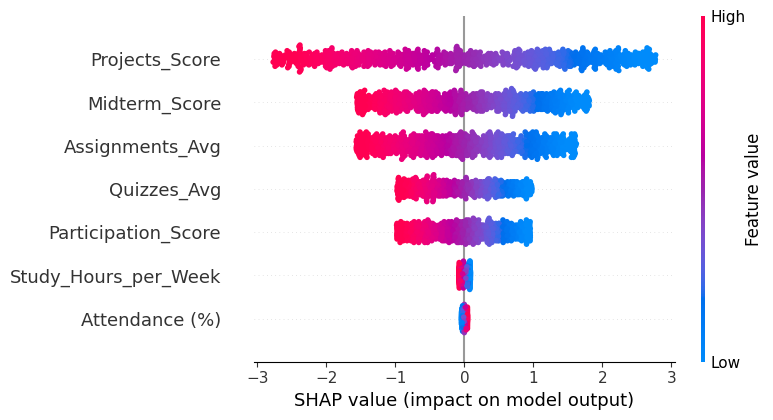


Overall SHAP Feature Importance:


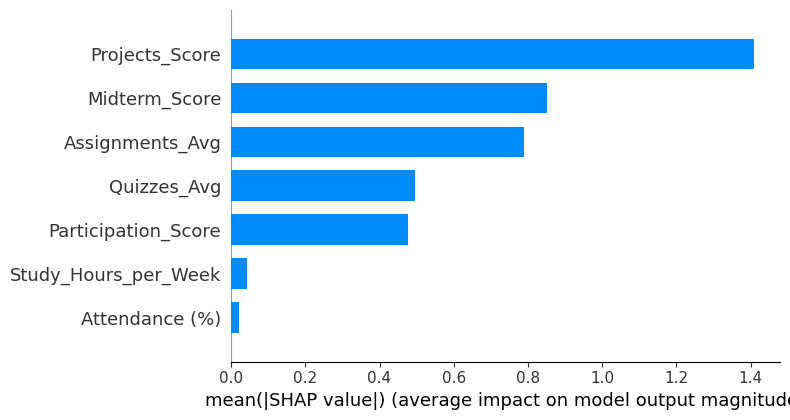

In [ ]:
# ================================================================
# EXPLAINABLE ML FOR STUDENT ACADEMIC RISK PREDICTION
# PHASE 5 ONWARDS: EDA → ML → EVALUATION → SHAP → PREDICTION
# Google Colab
# ================================================================


# ================================================================
# 0. IMPORT LIBRARIES
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("=" * 70)
print("EXPLAINABLE ML FOR STUDENT ACADEMIC RISK PREDICTION")
print("=" * 70)


# ================================================================
# PHASE 5: EXPLORATORY DATA ANALYSIS (EDA)
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 5: EXPLORATORY DATA ANALYSIS")
print("=" * 70)


# ------------------------------------------------
# 5.1 Dataset overview
# ------------------------------------------------

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nStatistical Summary:")
display(df[academic_features].describe())


# ------------------------------------------------
# 5.2 Academic Risk Distribution
# ------------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Academic_Risk"
)

plt.title("Distribution of Academic Risk")
plt.xlabel("Academic Risk")
plt.ylabel("Number of Students")
plt.show()


# ------------------------------------------------
# 5.3 Grade Distribution
# ------------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Grade",
    order=sorted(df["Grade"].dropna().unique())
)

plt.title("Distribution of Student Grades")
plt.xlabel("Grade")
plt.ylabel("Number of Students")
plt.show()


# ------------------------------------------------
# 5.4 Attendance Distribution
# ------------------------------------------------

plt.figure(figsize=(8, 5))

sns.histplot(
    df["Attendance (%)"],
    bins=20,
    kde=True
)

plt.title("Distribution of Student Attendance")
plt.xlabel("Attendance (%)")
plt.ylabel("Number of Students")
plt.show()


# ------------------------------------------------
# 5.5 Academic Score Distributions
# ------------------------------------------------

score_features = [
    "Midterm_Score",
    "Assignments_Avg",
    "Quizzes_Avg",
    "Participation_Score",
    "Projects_Score"
]

for feature in score_features:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        df[feature],
        bins=20,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Students")

    plt.show()


# ------------------------------------------------
# 5.6 Attendance vs Academic Risk
# ------------------------------------------------

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Academic_Risk",
    y="Attendance (%)"
)

plt.title("Attendance vs Academic Risk")
plt.xlabel("Academic Risk")
plt.ylabel("Attendance (%)")

plt.show()


# ------------------------------------------------
# 5.7 Midterm Score vs Academic Risk
# ------------------------------------------------

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Academic_Risk",
    y="Midterm_Score"
)

plt.title("Midterm Score vs Academic Risk")
plt.xlabel("Academic Risk")
plt.ylabel("Midterm Score")

plt.show()


# ------------------------------------------------
# 5.8 Correlation Heatmap
# ------------------------------------------------

plt.figure(figsize=(10, 7))

correlation = df[academic_features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Academic Features")

plt.show()


# ================================================================
# PHASE 6: FEATURE ENGINEERING / FEATURE SELECTION
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 6: FEATURE ENGINEERING")
print("=" * 70)


# We use the selected academic and attendance features.
# Grade, Total_Score and Final_Score are excluded to avoid
# target leakage and to make early academic-risk prediction
# more meaningful.

features = [
    "Attendance (%)",
    "Midterm_Score",
    "Assignments_Avg",
    "Quizzes_Avg",
    "Participation_Score",
    "Projects_Score",
    "Study_Hours_per_Week"
]

X = df[features].copy()

y = df["Academic_Risk_Num"].copy()


print("\nFinal Features Used by the ML Models:")

for i, feature in enumerate(features, start=1):
    print(f"{i}. {feature}")

print("\nTarget:")
print("0 = Not At Risk")
print("1 = At Risk")


# Check missing values in final features

print("\nMissing Values in Selected Features:")

print(X.isnull().sum())


# ================================================================
# PHASE 7: PREPARE TRAINING AND TESTING DATA
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 7: TRAINING AND TEST DATA")
print("=" * 70)


# Use the train-test split already created during preprocessing.
# Re-create it here to ensure X and y correspond exactly.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


# ================================================================
# PHASE 8: MACHINE LEARNING MODEL DEVELOPMENT
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 8: MACHINE LEARNING MODEL DEVELOPMENT")
print("=" * 70)


# ------------------------------------------------
# Model 1: Logistic Regression
# ------------------------------------------------

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])


# ------------------------------------------------
# Model 2: Decision Tree
# ------------------------------------------------

decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)


# ------------------------------------------------
# Model 3: Random Forest
# ------------------------------------------------

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42
)


models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}


# ------------------------------------------------
# Train all models
# ------------------------------------------------

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    print(f"{name} trained successfully!")


# ================================================================
# PHASE 9: MODEL EVALUATION AND COMPARISON
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 9: MODEL EVALUATION AND COMPARISON")
print("=" * 70)


results = []


for name, model in models.items():

    y_pred = model.predict(X_test)

    y_probability = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        y_probability
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })


results_df = pd.DataFrame(results)

print("\nModel Performance Comparison:")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


# ================================================================
# PHASE 10: FIND THE BEST MODEL
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 10: BEST MODEL SELECTION")
print("=" * 70)


# Select model based on F1 Score
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

best_model = models[best_model_name]


print("\nBest Model:")
print(best_model_name)

print(
    "\nThe best model was selected based on the highest F1 Score."
)


# ================================================================
# PHASE 11: DETAILED EVALUATION OF BEST MODEL
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 11: DETAILED BEST MODEL EVALUATION")
print("=" * 70)


best_predictions = best_model.predict(X_test)

best_probabilities = best_model.predict_proba(X_test)[:, 1]


print("\nClassification Report:")

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=[
            "Not At Risk",
            "At Risk"
        ],
        zero_division=0
    )
)


# ------------------------------------------------
# Confusion Matrix
# ------------------------------------------------

plt.figure(figsize=(7, 6))

cm = confusion_matrix(
    y_test,
    best_predictions
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not At Risk", "At Risk"],
    yticklabels=["Not At Risk", "At Risk"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


# ------------------------------------------------
# ROC Curve
# ------------------------------------------------

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    best_probabilities
)

plt.title(f"ROC Curve - {best_model_name}")

plt.show()


# ================================================================
# PHASE 12: CROSS-VALIDATION
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 12: CROSS-VALIDATION")
print("=" * 70)


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="f1"
    )

    print(f"\n{name}")
    print("F1 Scores:", np.round(scores, 4))
    print("Mean F1 Score:", round(scores.mean(), 4))


# ================================================================
# PHASE 13: FEATURE IMPORTANCE
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 13: FEATURE IMPORTANCE")
print("=" * 70)


# Feature importance is directly available for Decision Tree
# and Random Forest.

if best_model_name == "Random Forest":

    importance_values = best_model.feature_importances_

elif best_model_name == "Decision Tree":

    importance_values = best_model.feature_importances_

else:

    # Logistic Regression is inside a Pipeline.
    # Extract coefficients from the classifier.

    importance_values = np.abs(
        best_model.named_steps["classifier"].coef_[0]
    )


feature_importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
display(feature_importance_df)


plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature"
)

plt.title(f"Feature Importance - {best_model_name}")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()


# ================================================================
# PHASE 14: SHAP EXPLAINABLE AI
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 14: EXPLAINABLE AI USING SHAP")
print("=" * 70)


# Install SHAP if necessary

!pip -q install shap

import shap


print("\nGenerating SHAP explanations...")


# ------------------------------------------------
# SHAP for Random Forest / Decision Tree
# ------------------------------------------------

if best_model_name in ["Random Forest", "Decision Tree"]:

    explainer = shap.TreeExplainer(best_model)

    shap_values = explainer.shap_values(X_test)

    # SHAP versions can return either:
    # list of arrays or a 3D array.

    if isinstance(shap_values, list):

        shap_values_positive = shap_values[1]

    else:

        if len(shap_values.shape) == 3:

            shap_values_positive = shap_values[:, :, 1]

        else:

            shap_values_positive = shap_values


# ------------------------------------------------
# SHAP for Logistic Regression
# ------------------------------------------------

else:

    # Transform the test data using the scaler inside the pipeline.

    X_test_scaled_for_shap = (
        best_model.named_steps["scaler"]
        .transform(X_test)
    )

    logistic_classifier = (
        best_model.named_steps["classifier"]
    )

    explainer = shap.LinearExplainer(
        logistic_classifier,
        X_test_scaled_for_shap
    )

    shap_values_positive = explainer.shap_values(
        X_test_scaled_for_shap
    )


# ------------------------------------------------
# SHAP Summary Plot
# ------------------------------------------------

print("\nSHAP Summary Plot:")

shap.summary_plot(
    shap_values_positive,
    X_test,
    feature_names=features
)


# ------------------------------------------------
# SHAP Bar Plot
# ------------------------------------------------

print("\nOverall SHAP Feature Importance:")

shap.summary_plot(
    shap_values_positive,
    X_test,
    feature_names=features,
    plot_type="bar"
)

In [ ]:
# ================================================================
# PHASE 15: INDIVIDUAL STUDENT PREDICTION
# ================================================================

print("\n\n")
print("=" * 70)
print("PHASE 15: INDIVIDUAL STUDENT RISK PREDICTION")
print("=" * 70)


# ------------------------------------------------
# Show available students
# ------------------------------------------------

print("\nNumber of students available:", len(df))


# ================================================================
# CREATE FUNCTION FOR STUDENT PREDICTION
# ================================================================

def predict_student(student_id):

    """
    Predict academic risk for one existing student
    and provide an explanation.
    """

    # Find student
    student_data = df[
        df["Student_ID"].astype(str) == str(student_id)
    ]

    if student_data.empty:

        print("\nStudent ID not found.")

        return


    # Get student features
    student_features = student_data[features].copy()


    # Prediction
    prediction = best_model.predict(
        student_features
    )[0]


    # Probability
    probability = best_model.predict_proba(
        student_features
    )[0]


    risk_probability = probability[1] * 100
    safe_probability = probability[0] * 100


    # ------------------------------------------------
    # Display student information
    # ------------------------------------------------

    print("\n")
    print("=" * 60)
    print("STUDENT INFORMATION")
    print("=" * 60)

    print("Student ID:", student_id)

    print("\nStudent Academic Information:")

    display(
        student_data[
            [
                "Attendance (%)",
                "Midterm_Score",
                "Assignments_Avg",
                "Quizzes_Avg",
                "Participation_Score",
                "Projects_Score",
                "Study_Hours_per_Week"
            ]
        ]
    )


    # ------------------------------------------------
    # Display prediction
    # ------------------------------------------------

    print("=" * 60)
    print("PREDICTION RESULT")
    print("=" * 60)

    if prediction == 1:

        print("\nPREDICTION: AT RISK")

    else:

        print("\nPREDICTION: NOT AT RISK")


    print(
        f"\nProbability of At Risk: {risk_probability:.2f}%"
    )

    print(
        f"Probability of Not At Risk: {safe_probability:.2f}%"
    )


    # ============================================================
    # SHAP EXPLANATION FOR INDIVIDUAL STUDENT
    # ============================================================

    print("\n")
    print("=" * 60)
    print("WHY DID THE MODEL MAKE THIS PREDICTION?")
    print("=" * 60)


    # ------------------------------------------------
    # Prepare SHAP input
    # ------------------------------------------------

    if best_model_name in ["Random Forest", "Decision Tree"]:

        individual_shap = explainer.shap_values(
            student_features
        )

        if isinstance(individual_shap, list):

            individual_shap_values = individual_shap[1][0]

        else:

            if len(individual_shap.shape) == 3:

                individual_shap_values = individual_shap[0, :, 1]

            else:

                individual_shap_values = individual_shap[0]


    else:

        student_scaled = (
            best_model.named_steps["scaler"]
            .transform(student_features)
        )

        individual_shap_values = explainer.shap_values(
            student_scaled
        )[0]


    # ------------------------------------------------
    # Create explanation table
    # ------------------------------------------------

    explanation_df = pd.DataFrame({
        "Feature": features,
        "SHAP Value": individual_shap_values,
        "Student Value": student_features.iloc[0].values
    })


    explanation_df["Absolute Impact"] = (
        explanation_df["SHAP Value"].abs()
    )


    explanation_df = explanation_df.sort_values(
        by="Absolute Impact",
        ascending=False
    )


    print("\nFactors with the strongest influence:")

    display(
        explanation_df[
            [
                "Feature",
                "Student Value",
                "SHAP Value"
            ]
        ]
    )


    # ------------------------------------------------
    # Individual SHAP waterfall plot
    # ------------------------------------------------

    print("\nIndividual Student Explanation:")

    if best_model_name in ["Random Forest", "Decision Tree"]:

        # Generate an Explanation object for waterfall plot

        try:

            if isinstance(individual_shap, list):

                base_value = explainer.expected_value[1]

            else:

                if len(individual_shap.shape) == 3:

                    base_value = explainer.expected_value[1]

                else:

                    base_value = explainer.expected_value


            explanation = shap.Explanation(
                values=individual_shap_values,
                base_values=base_value,
                data=student_features.iloc[0].values,
                feature_names=features
            )

            shap.plots.waterfall(
                explanation,
                max_display=10
            )

        except Exception as e:

            print(
                "Waterfall plot could not be generated:",
                e
            )


    else:

        try:

            base_value = explainer.expected_value

            explanation = shap.Explanation(
                values=individual_shap_values,
                base_values=base_value,
                data=student_features.iloc[0].values,
                feature_names=features
            )

            shap.plots.waterfall(
                explanation,
                max_display=10
            )

        except Exception as e:

            print(
                "Waterfall plot could not be generated:",
                e
            )


    # ------------------------------------------------
    # Simple textual explanation
    # ------------------------------------------------

    print("\n")
    print("=" * 60)
    print("KEY FACTORS")
    print("=" * 60)


    top_factors = explanation_df.head(4)


    for _, row in top_factors.iterrows():

        feature = row["Feature"]
        shap_value = row["SHAP Value"]
        value = row["Student Value"]


        if shap_value > 0:

            print(
                f"• {feature} = {value} "
                f"contributed toward higher risk."
            )

        else:

            print(
                f"• {feature} = {value} "
                f"contributed toward lower risk."
            )


    print("\nPrediction completed.")


# ================================================================
# PHASE 16: STUDENT SELECTION MENU
# ================================================================

print("\n\n")
print("=" * 70)
print("STUDENT SELECTION MENU")
print("=" * 70)


# Display first 20 student IDs

student_ids = df["Student_ID"].astype(str).tolist()

print("\nExample Student IDs:")

for student in student_ids[:20]:

    print(student)


print("\nTotal available students:", len(student_ids))


# ------------------------------------------------
# Enter Student ID
# ------------------------------------------------

selected_student = input(
    "\nEnter Student ID to predict risk: "
)


predict_student(selected_student)


# ================================================================
# PHASE 17: PREDICTION FOR A NEW STUDENT
# ================================================================

print("\n\n")
print("=" * 70)
print("OPTIONAL: PREDICT RISK FOR A NEW STUDENT")
print("=" * 70)


def predict_new_student(
    attendance,
    midterm,
    assignments,
    quizzes,
    participation,
    projects,
    study_hours
):

    """
    Predict risk for a student whose data is not already
    present in the dataset.
    """

    new_student = pd.DataFrame({

        "Attendance (%)": [attendance],

        "Midterm_Score": [midterm],

        "Assignments_Avg": [assignments],

        "Quizzes_Avg": [quizzes],

        "Participation_Score": [participation],

        "Projects_Score": [projects],

        "Study_Hours_per_Week": [study_hours]

    })


    prediction = best_model.predict(
        new_student
    )[0]


    probability = best_model.predict_proba(
        new_student
    )[0]


    print("\n")
    print("=" * 60)
    print("NEW STUDENT PREDICTION")
    print("=" * 60)


    if prediction == 1:

        print("\nPREDICTION: AT RISK")

    else:

        print("\nPREDICTION: NOT AT RISK")


    print(
        f"\nAt Risk Probability: {probability[1] * 100:.2f}%"
    )

    print(
        f"Not At Risk Probability: {probability[0] * 100:.2f}%"
    )


    # ------------------------------------------------
    # SHAP explanation
    # ------------------------------------------------

    if best_model_name in ["Random Forest", "Decision Tree"]:

        new_shap = explainer.shap_values(
            new_student
        )

        if isinstance(new_shap, list):

            new_shap_values = new_shap[1][0]

        else:

            if len(new_shap.shape) == 3:

                new_shap_values = new_shap[0, :, 1]

            else:

                new_shap_values = new_shap[0]

    else:

        new_student_scaled = (
            best_model.named_steps["scaler"]
            .transform(new_student)
        )

        new_shap_values = explainer.shap_values(
            new_student_scaled
        )[0]


    new_explanation = pd.DataFrame({

        "Feature": features,

        "Student Value": new_student.iloc[0].values,

        "SHAP Value": new_shap_values

    })


    new_explanation["Absolute Impact"] = (
        new_explanation["SHAP Value"].abs()
    )


    new_explanation = new_explanation.sort_values(
        by="Absolute Impact",
        ascending=False
    )


    print("\nMain factors affecting this prediction:")

    display(
        new_explanation[
            [
                "Feature",
                "Student Value",
                "SHAP Value"
            ]
        ]
    )




PHASE 15: INDIVIDUAL STUDENT RISK PREDICTION

Number of students available: 5000



STUDENT SELECTION MENU

Example Student IDs:
S1000
S1001
S1002
S1003
S1004
S1005
S1006
S1007
S1008
S1009
S1010
S1011
S1012
S1013
S1014
S1015
S1016
S1017
S1018
S1019

Total available students: 5000


In [ ]:
!pip install streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 66.3 MB/s eta 0:00:00


In [ ]:
!pip install -q gradio

In [ ]:

import gradio as gr
import pandas as pd


def predict_risk(
    attendance,
    midterm,
    assignments,
    quizzes,
    participation,
    projects,
    study_hours
):

    student_data = pd.DataFrame([{
        "Attendance (%)": attendance,
        "Midterm_Score": midterm,
        "Assignments_Avg": assignments,
        "Quizzes_Avg": quizzes,
        "Participation_Score": participation,
        "Projects_Score": projects,
        "Study_Hours_per_Week": study_hours
    }])


    prediction = best_model.predict(student_data)[0]
    probabilities = best_model.predict_proba(student_data)[0]

    risk_probability = probabilities[1] * 100
    safe_probability = probabilities[0] * 100

    if prediction == 1:
        result = "AT RISK"
        advice = (
            "The model predicts academic risk. "
            "Consider reviewing attendance, test scores, "
            "assignments and study habits."
        )
    else:
        result = "NOT AT RISK"
        advice = (
            "The model does not predict academic risk "
            "for these input values."
        )

    return (
        f"Prediction: {result}\n\n"
        f"At-risk probability: {risk_probability:.2f}%\n"
        f"Not-at-risk probability: {safe_probability:.2f}%\n\n"
        f"Advice: {advice}"
    )



demo = gr.Interface(
    fn=predict_risk,
    inputs=[
        gr.Number(label="Attendance (%)", value=75),
        gr.Number(label="Midterm Score", value=70),
        gr.Number(label="Assignments Average", value=70),
        gr.Number(label="Quizzes Average", value=70),
        gr.Number(label="Participation Score", value=70),
        gr.Number(label="Projects Score", value=70),
        gr.Number(label="Study Hours per Week", value=10)
    ],
    outputs=gr.Textbox(
        label="Academic Risk Prediction",
        lines=7
    ),
    title="Student Academic Risk Prediction",
    description=(
        "Enter the student's academic details "
        "to predict academic risk using Machine Learning."
    ),
    theme=gr.themes.Soft()
)


demo.launch(share=True)


/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6f843ba322939d5425.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
